In [1]:
import numpy as np
from matplotlib import pyplot as plt

In [2]:
n = 10000
n_hidden = 64
Wrec_free = np.random.randn(n, n_hidden, n_hidden)/np.sqrt(n_hidden)
# Wrec_free = np.random.randn(n, n_hidden, n_hidden) * 1.5
# Wrec_free = np.random.uniform(-1, 1, size=(n, n_hidden, n_hidden))
# Wrec_free = np.random.exponential(scale=1/np.sqrt(n_hidden), size=(n, n_hidden, n_hidden))
def relu(x):
    return np.where(x > 0, x, 0)
def absolute(x):
    return np.where(x > 0, x, -x)
filter = absolute
# eimask_logit = np.random.randint(0,2, size=(n, n_hidden)) * 2 - 1
eimask_logit = np.random.choice([0, 1], size=(n, n_hidden), p=[0.5, 0.5]) * 2 - 1
# transfer logit to diagonal matrix
corrected_weight = np.array([filter(Wrec_free[i]) @ np.diag(eimask_logit[i]) for i in range(n)])
# calculate distribution of eigenvalues
eigvals = np.linalg.eigvals(corrected_weight)
real_parts = np.real(eigvals)
imag_parts = np.imag(eigvals)


Wrec_simple = np.random.randn(n, n_hidden, n_hidden)/np.sqrt(n_hidden)
# Wrec_simple = np.random.randn(n, n_hidden, n_hidden) * 1.5
# Wrec_simple = np.random.uniform(-1, 1, size=(n, n_hidden, n_hidden))
eigvals_simple = np.linalg.eigvals(Wrec_simple)
real_parts_simple = np.real(eigvals_simple)
imag_parts_simple = np.imag(eigvals_simple)

In [3]:
singular_values = np.linalg.svd(corrected_weight, compute_uv=False)
singular_values_simple = np.linalg.svd(Wrec_simple, compute_uv=False)

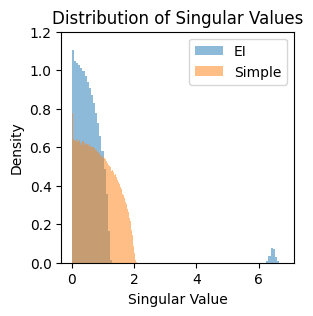

In [4]:

fig, ax = plt.subplots(1, 1, figsize=(3,3))
ax.set_ylim([0,1.2])
ax.hist(singular_values.flatten(), bins=100, density=True, alpha=0.5, label='EI')
ax.hist(singular_values_simple.flatten(), bins=100, density=True, alpha=0.5, label='Simple')
ax.set_title('Distribution of Singular Values')
ax.set_xlabel('Singular Value')
ax.set_ylabel('Density')
ax.legend()
plt.show()

/tmp/ipykernel_2271/3068942268.py:20: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/home/geert/anaconda3/envs/neurogym/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


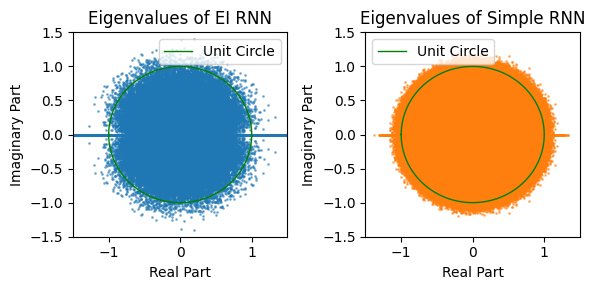

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].scatter(real_parts, imag_parts, s=1, alpha=0.5, color='C0')
ax[0].set_title('Eigenvalues of EI RNN')
ax[0].set_xlabel('Real Part')
ax[0].set_ylabel('Imaginary Part')
ax[1].scatter(real_parts_simple, imag_parts_simple, s=1, alpha=0.5, color='C1')
ax[1].set_title('Eigenvalues of Simple RNN')
ax[1].set_xlabel('Real Part')
ax[1].set_ylabel('Imaginary Part')
for a in ax:
    a.set_xlim([-1.5, 1.5])
    a.set_ylim([-1.5, 1.5])
xs = np.linspace(-np.pi, np.pi, 100)
cosxs = np.cos(xs)
sinxs = np.sin(xs)
ax[0].plot(cosxs, sinxs, color='g', linewidth=1, linestyle='-', label='Unit Circle')
ax[1].plot(cosxs, sinxs, color='g', linewidth=1, linestyle='-', label='Unit Circle')
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.show()

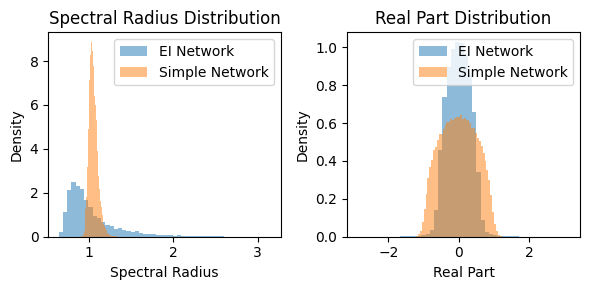

In [6]:
spectral_radius_ei = np.max(np.abs(eigvals), -1)
spectral_radius_simple = np.max(np.abs(eigvals_simple), -1)
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].hist(spectral_radius_ei, bins=50, alpha=0.5, label='EI Network', color='C0', density=True)
ax[0].hist(spectral_radius_simple, bins=50, alpha=0.5, label='Simple Network', color='C1', density=True)
ax[0].set_title('Spectral Radius Distribution')
ax[0].set_xlabel('Spectral Radius')
ax[0].set_ylabel('Density')
ax[0].legend()
ax[1].hist(real_parts.flatten(), bins=50, alpha=0.5, label='EI Network', color='C0', density=True)
ax[1].hist(real_parts_simple.flatten(), bins=50, alpha=0.5, label='Simple Network', color='C1', density=True)
ax[1].set_title('Real Part Distribution')
ax[1].set_xlabel('Real Part')
ax[1].set_ylabel('Density')
ax[1].legend()
plt.tight_layout()
plt.show()

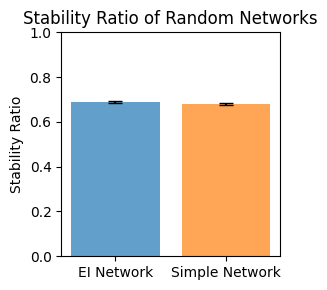

In [7]:
def is_stable(W):
    det = np.linalg.det(W)
    trace = np.trace(W, axis1=1, axis2=2)
    return (np.abs(det) < 1) & (1+det>np.abs(trace))
ei_stable = is_stable(corrected_weight)
simple_stable = is_stable(Wrec_simple)
ei_stable_mean = np.mean(ei_stable)
simple_stable_mean = np.mean(simple_stable)
ei_stable_std = np.std(ei_stable)/np.sqrt(n)
simple_stable_std = np.std(simple_stable)/np.sqrt(n)
fig, ax = plt.subplots(1, 1, figsize=(3,3))
ax.bar(['EI Network', 'Simple Network'], [ei_stable_mean, simple_stable_mean],
       yerr=[ei_stable_std, simple_stable_std], color=['C0', 'C1'], alpha=0.7)
ax.errorbar(['EI Network', 'Simple Network'], [ei_stable_mean, simple_stable_mean],
            yerr=[ei_stable_std, simple_stable_std], fmt='none', capsize=5, color='black')
ax.set_title('Stability Ratio of Random Networks')
ax.set_ylabel('Stability Ratio')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()